In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors


In [2]:
# таблица с уникальными идентификаторами пользователей
users = pd.read_csv('data/olist_customers_dataset.csv')

# таблица заказов
orders = pd.read_csv('data/olist_orders_dataset.csv')

# товарные позиции, входящие в заказы
products = pd.read_csv('data/olist_order_items_dataset.csv')

In [3]:
users.head(2)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP


In [4]:
orders.head(2)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00


In [5]:
products.head(2)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93


##### **Задача 1. Оценить месячный retention в оформление заказа с помощью когортного анализа.**

Для retention в оформление заказа нам нужны только успешно оформленные заказы.

Исследуем статус — delivered. canceled/unavailable — не оформленный заказ. А остальные промежуточные в зависшем пока состоянии, возможно что и не будут доставлены.

In [6]:
# Распределение статусов заказов
orders['order_status'].value_counts()

# Доля каждого статуса
orders['order_status'].value_counts(normalize=True)

order_status
delivered      0.970203
shipped        0.011132
canceled       0.006285
unavailable    0.006124
invoiced       0.003158
processing     0.003027
created        0.000050
approved       0.000020
Name: proportion, dtype: float64

Доля доставленных заказов 97%, значит можно работать с этой метрикой.

In [7]:
# Оставим только доставленные заказы для retention
delivered_orders = orders[orders['order_status'] == 'delivered'].copy()

In [8]:
# Добавляем customer_unique_id к доставленным заказам
delivered_orders = delivered_orders.merge(
    users[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

delivered_orders[['order_id', 'customer_unique_id', 'order_purchase_timestamp']].head()


,order_id,customer_unique_id,order_purchase_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49
3,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,2017-11-18 19:28:06
4,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13 21:18:39


Определим месяц первого заказа пользователя — месяц когорты. 

In [9]:
# Приводим дату заказа к типу datetime
delivered_orders['order_purchase_timestamp'] = pd.to_datetime(delivered_orders['order_purchase_timestamp'])

# Извлекаем месяц заказа
delivered_orders['order_month'] = (delivered_orders['order_purchase_timestamp'].dt.to_period('M'))

# Месяц первого заказа пользователя = месяц когорты
delivered_orders['cohort_month'] = (delivered_orders.groupby('customer_unique_id')['order_month'].transform('min'))

# Возраст заказа в месяцах (0 — месяц первого заказа)
delivered_orders['month_number'] = (
    (delivered_orders['order_month'].dt.year - delivered_orders['cohort_month'].dt.year) * 12
    + (delivered_orders['order_month'].dt.month - delivered_orders['cohort_month'].dt.month)
)

# Размер когорты = число уникальных пользователей в месяц первого заказа
cohort_size = (delivered_orders.groupby('cohort_month')['customer_unique_id'].nunique().rename('cohort_size'))

# Уникальные пользователи по когорте и месяцу жизни
retention = (delivered_orders.groupby(['cohort_month', 'month_number'])['customer_unique_id'].nunique().reset_index())

# Делим на размер когорты
retention = retention.merge(cohort_size, on='cohort_month', how='left')
retention['retention'] = retention['customer_unique_id'] / retention['cohort_size']

# Создаем сводную таблицу для когортного анализа
retention_pivot = retention.pivot(index='cohort_month',columns='month_number',values='retention')

retention_pivot

month_number,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,1.0,NaN,NaN,NaN,NaN,NaN,0.003817,NaN,NaN,0.003817,NaN,0.003817,NaN,0.003817,NaN,0.003817,NaN,0.003817,0.007634,0.007634
2016-12,1.0,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,1.0,0.002789,0.002789,0.001395,0.004184,0.001395,0.004184,0.001395,0.001395,NaN,0.004184,0.001395,0.006974,0.004184,0.001395,0.001395,0.002789,0.004184,0.001395,NaN
2017-02,1.0,0.001843,0.003071,0.001229,0.004300,0.001229,0.002457,0.001843,0.001229,0.001843,0.001229,0.003071,0.001229,0.001843,0.001229,0.000614,0.000614,0.001843,NaN,NaN
2017-03,1.0,0.004395,0.003596,0.003995,0.003596,0.001598,0.001598,0.003196,0.003196,0.000799,0.003596,0.001199,0.001998,0.001199,0.001598,0.002397,0.000799,0.001199,NaN,NaN
2017-04,1.0,0.006206,0.002216,0.001773,0.002660,0.002660,0.003546,0.003103,0.003103,0.001773,0.002660,0.000887,0.000443,0.000443,0.000887,0.000887,0.001330,NaN,NaN,NaN
2017-05,1.0,0.004636,0.004636,0.002898,0.002898,0.003187,0.004057,0.001449,0.002608,0.002608,0.002608,0.003477,0.002318,0.000290,0.001739,0.002028,NaN,NaN,NaN,NaN
2017-06,1.0,0.004939,0.003951,0.004281,0.002963,0.003951,0.003622,0.002305,0.001317,0.001976,0.002963,0.003622,0.001646,0.001646,0.002305,NaN,NaN,NaN,NaN,NaN


Проанализируем, чему равен медианный retention 1-го месяца (т.е. возьмем retention 1-ого месяца для всех когорт и посчитаем по этим числам медиану).

In [10]:
# Берём retention 1-го месяца по всем когортам
retention_m1 = retention_pivot[1].dropna()

# Исключаем аномальные ранние когорты 2016 года (очень маленькие)
retention_m1_clean = retention_m1[retention_m1.index >= '2017-01-01']

median_retention_m1 = retention_m1_clean.median()
print(f'Медианный retention 1-го месяца: {median_retention_m1:.4%}')


Медианный retention 1-го месяца: 0.4939%


Найдем когорту с самым высоким retention на 3-й месяц.

In [11]:
# Retention 3-го месяца по всем когортам
retention_m3 = retention_pivot[3].dropna()

# Топ-3 когорты
retention_m3.sort_values(ascending=False).head(3)

cohort_month
2017-06    0.004281
2017-03    0.003995
2017-12    0.003372
Freq: M, Name: 3, dtype: float64

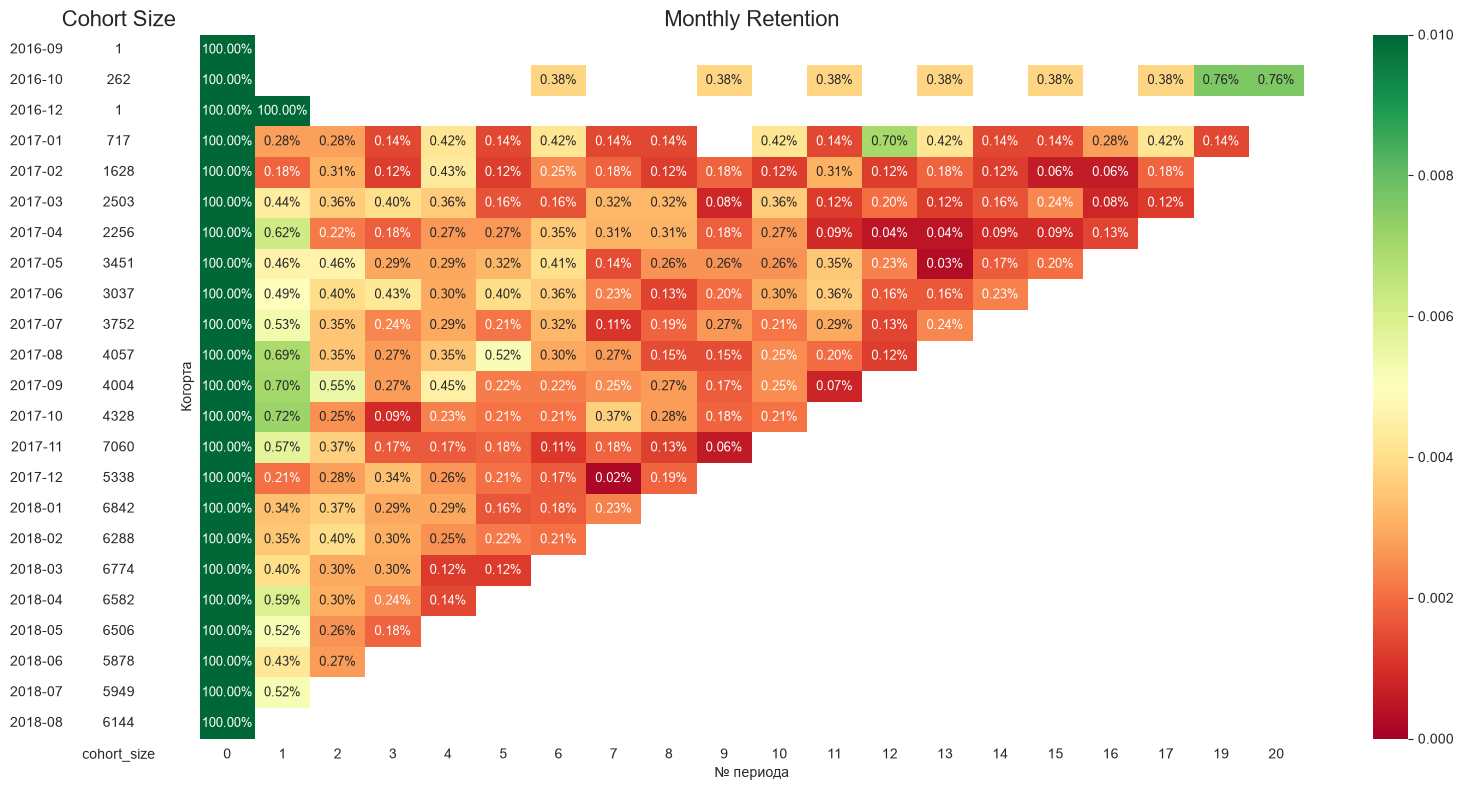

In [12]:
retention_matrix = retention_pivot

# Размеры когорт в виде DataFrame с тем же индексом, что у retention_pivot
cohort_size_df = cohort_size.to_frame(name='cohort_size')

# Строим тепловую карту когортного анализа
with sns.axes_style("white"):
    fig, ax = plt.subplots(
        1, 2,
        figsize=(16, 8),
        sharey=True,
        gridspec_kw={'width_ratios': [1, 15]}
    )

    # Тепловая карта retention
    sns.heatmap(
        retention_matrix,
        mask=retention_matrix.isnull(),
        annot=True,
        fmt='.2%',
        cmap='RdYlGn',
        vmin=0,
        vmax=0.01,        # ограничиваем шкалу реальным диапазоном ~1%
        ax=ax[1],
        annot_kws={'size': 9}
    )
    ax[1].set_title('Monthly Retention', fontsize=16)
    ax[1].set(xlabel='№ периода', ylabel='Когорта')

    # Тепловая карта размеров когорт
    white_cmap = mcolors.ListedColormap(['white'])
    sns.heatmap(
        cohort_size_df,
        annot=True,
        cbar=False,
        fmt='g',
        cmap=white_cmap,
        ax=ax[0],
        annot_kws={'size': 10}
    )
    ax[0].set_title('Cohort Size', fontsize=16)
    ax[0].set_ylabel('')

    fig.tight_layout()
    plt.show()

**Вывод.** Маркетплейс не удерживает клиентов: медианный retention 1-го месяца 0.4939%, и дальше он падает. 

##### **Задача 2. Определить, существует ли product/market fit у маркетплейса.**

In [13]:
# посчитаем долю пользователей, совершивших ≥ 2 заказа
orders_per_user = (delivered_orders.groupby('customer_unique_id')['order_id'].nunique())

repeat_rate = (orders_per_user > 1).mean()
print(f'Доля клиентов с повторными покупками: {repeat_rate:.2%}')

Доля клиентов с повторными покупками: 3.00%


PMF в e-commerce принято оценивать по двум признакам:

**Уровень retention** — возвращается ли клиент после первой покупки.

**Стабильность retention между когортами** — не ухудшается ли удержание по мере роста (или хотя бы держится на одном уровне).

Что есть у нас:

1. retention 1-го месяца 0.4939%, и дальше он падает
2. лучшая когорта — ~0.7% (2017-09, 2017-10)
3. между когортами retention не растёт, хотя растет количество клиентов
4. повторные покупки — единичны (3% клиентов)

**Делаем вывод:** PMF отсутствует

Причины: 

1. разовый характер покупок (товары не расходники и редко требуют обновления)
2. ассортимент, ценность (клиент покупает на пробу и не видит поводов вернуться)
3. возможные проблемы с доставкой/ассортиментом.

Какие шаги можно предпринять:
1. попробовать сегменитровать клиентов (по категориям, каналам привлечения), возможо где-то и будет более высокий retention
2. искать нишу, где retention выше
2. работать над повторными покупками (email, лояльность, рекомендации)


Посмотрим распределение числа заказов клиента

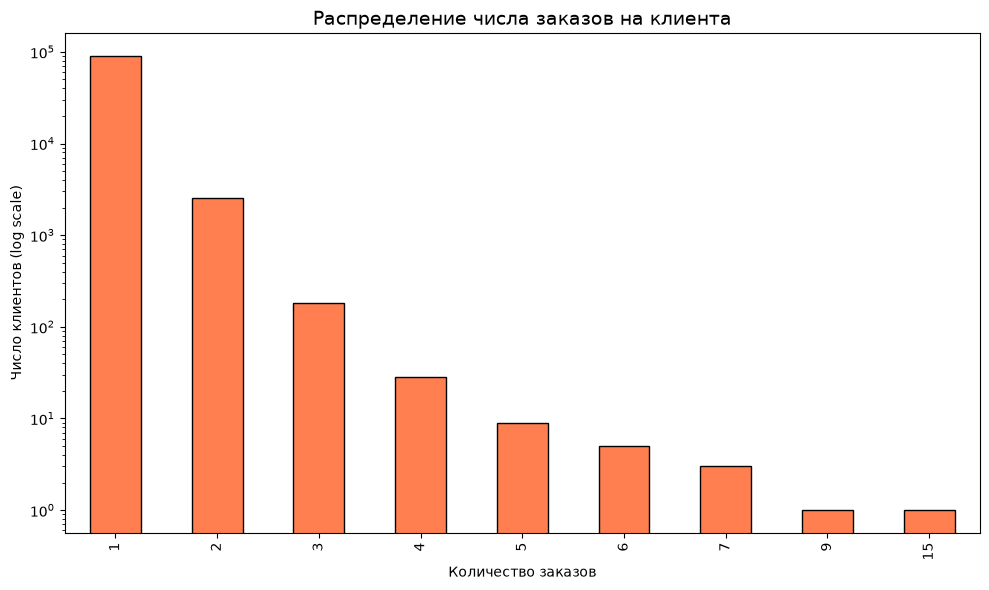

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))

orders_per_user.value_counts().sort_index().plot(
    kind='bar', ax=ax, color='coral', edgecolor='black'
)
ax.set_title('Распределение числа заказов на клиента', fontsize=14)
ax.set_xlabel('Количество заказов')
ax.set_ylabel('Число клиентов (log scale)')
ax.set_yscale('log')
plt.tight_layout()
plt.show()

На графике хорошо видно, что почти все клиенты покупают 1 раз.

##### **Задача 3. Определить 5 основных метрик, на которых продакт может сконцентрироваться, чтобы максимизировать прибыль компании.**

Определим 5 основных метрик, на которых продакт может сконцентрироваться, чтобы максимизировать прибыль компании.

1. Рост объёма продаж: общая стоимость проданных товаров GMV.
2. Объём аудитории, которой продукт доставляет ценность: уникальные клиенты, оформившие заказ в месяц MAU.
3. Заинтересованность новых клиентов: доля новых пользователей, оформивших первый заказ, от всех зарегистрировавшихся.
4. Вовлечённость в продолжение использования: доля клиентов, совершивших ≥ 2 заказа.
5. Денежное выражение вовлечённости: средняя выручка на пользователя ARPU.

In [15]:
# Сумма по заказу (может быть несколько позиций)
order_value = (products.groupby('order_id').agg(order_price=('price', 'sum'),order_freight=('freight_value', 'sum')).reset_index())

# Джойним к доставленным заказам
orders_with_value = delivered_orders.merge(order_value,on='order_id',how='left')

# Проверка: не потеряли ли заказы
print('Заказов до merge:', delivered_orders.shape[0])
print('Заказов после merge:', orders_with_value.shape[0])
print('Пропусков в order_price:', orders_with_value['order_price'].isna().sum())

Заказов до merge: 96478
Заказов после merge: 96478
Пропусков в order_price: 0


In [16]:
orders_with_value.head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,order_month,cohort_month,month_number,order_price,order_freight
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,2017-10,2017-09,1,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,2018-07,2018-07,0,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,2018-08,2018-08,0,159.90,19.22


**Метрика 1 — Рост объёма продаж: общая стоимость проданных товаров GMV.**

In [17]:
orders_with_value['order_month'] = orders_with_value['order_month'].dt.to_timestamp()
gmv_monthly = (orders_with_value.groupby('order_month')['order_price'].sum().reset_index().rename(columns={'order_price': 'gmv'}))
gmv_monthly.head()

,order_month,gmv
0,2016-09-01,134.97
1,2016-10-01,40325.11
2,2016-12-01,10.90
3,2017-01-01,111798.36
4,2017-02-01,234223.40


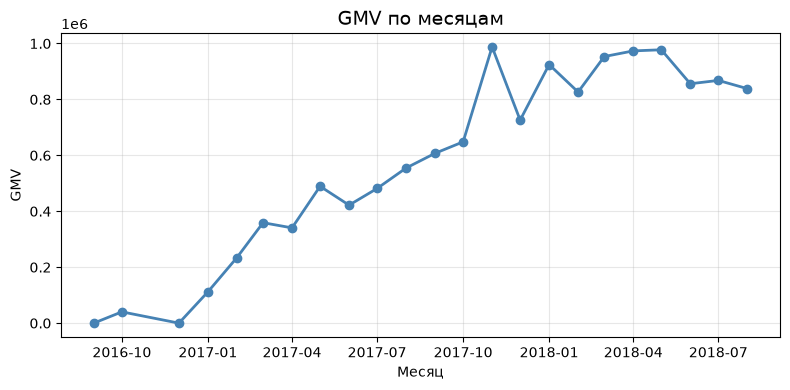

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gmv_monthly['order_month'], gmv_monthly['gmv'],
        marker='o', color='steelblue', linewidth=2)
ax.set_title('GMV по месяцам', fontsize=14)
ax.set_xlabel('Месяц')
ax.set_ylabel('GMV')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Метрика 2. Объём аудитории, которой продукт доставляет ценность: уникальные клиенты, оформившие заказ в месяц MAU.**

In [19]:
mau_monthly = (
    orders_with_value
    .groupby('order_month')['customer_unique_id']
    .nunique()
    .reset_index()
    .rename(columns={'customer_unique_id': 'mau'})
)

mau_monthly.head()

,order_month,mau
0,2016-09-01,1
1,2016-10-01,262
2,2016-12-01,1
3,2017-01-01,718
4,2017-02-01,1630


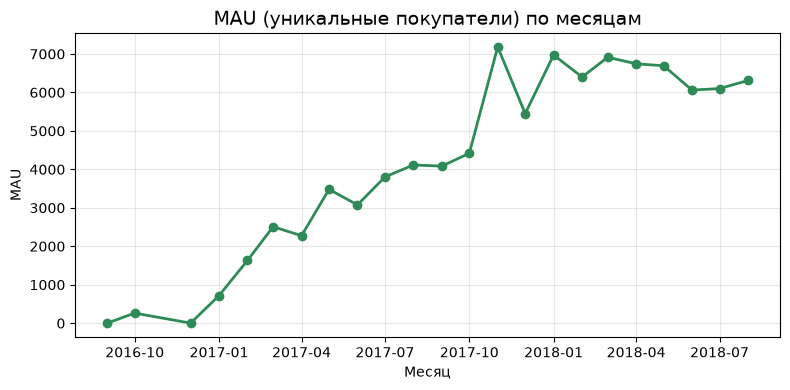

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mau_monthly['order_month'], mau_monthly['mau'],
        marker='o', color='seagreen', linewidth=2)
ax.set_title('MAU (уникальные покупатели) по месяцам', fontsize=14)
ax.set_xlabel('Месяц')
ax.set_ylabel('MAU')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Метрика 4. Вовлечённость в продолжение использования: доля клиентов, совершивших ≥ 2 заказа (Repeat Purchase Rate).**

Считаем по календарным месяцам: для каждого месяца смотрим, какая доля активных клиентов в этом месяце совершали заказ и раньше.

In [21]:
orders_with_value.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,order_month,cohort_month,month_number,order_price,order_freight
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,2017-10-01,2017-09,1,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,2018-07-01,2018-07,0,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-01,2018-08,0,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,2017-11-01,2017-11,0,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-01,2018-02,0,19.90,8.72


In [22]:
# Первый заказ клиента
first_order = (orders_with_value.groupby('customer_unique_id')['order_month'].min().rename('first_order_month').reset_index())

orders_with_value = orders_with_value.merge(first_order,on='customer_unique_id',how='left')

orders_with_value['is_repeat'] = (orders_with_value['order_month'] > orders_with_value['first_order_month'])

# Для каждого пользователя в каждом месяце — был ли повторный заказ 
user_month_repeat = (orders_with_value.groupby(['order_month', 'customer_unique_id'])['is_repeat'].max().reset_index())

# Repeat Purchase Rate по месяцам
rpr_monthly = (
    user_month_repeat
    .groupby('order_month')
    .agg(
        total_users=('customer_unique_id', 'nunique'),
        repeat_users=('is_repeat', 'sum')
    )
    .reset_index()
)

rpr_monthly['repeat_rate'] = rpr_monthly['repeat_users'] / rpr_monthly['total_users']

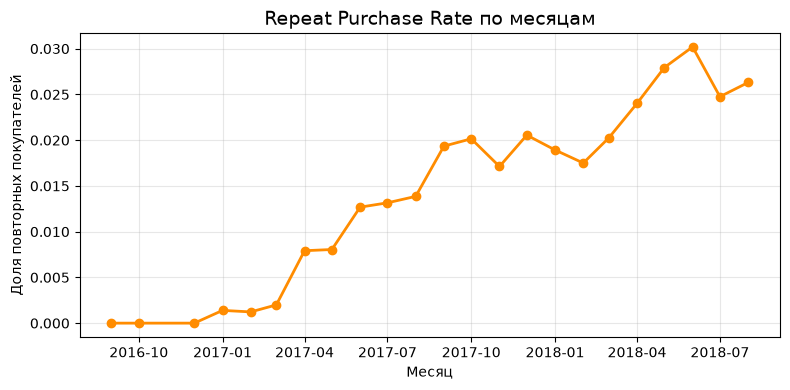

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(rpr_monthly['order_month'], rpr_monthly['repeat_rate'],
        marker='o', color='darkorange', linewidth=2)
ax.set_title('Repeat Purchase Rate по месяцам', fontsize=14)
ax.set_xlabel('Месяц')
ax.set_ylabel('Доля повторных покупателей')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Метрика 5. Денежное выражение вовлечённости: средняя выручка на пользователя ARPU.**

In [24]:
arpu_monthly = gmv_monthly.merge(mau_monthly, on='order_month')
arpu_monthly['arpu'] = arpu_monthly['gmv'] / arpu_monthly['mau']

arpu_monthly.head()

,order_month,gmv,mau,arpu
0,2016-09-01,134.97,1,134.970000
1,2016-10-01,40325.11,262,153.912634
2,2016-12-01,10.90,1,10.900000
3,2017-01-01,111798.36,718,155.708022
4,2017-02-01,234223.40,1630,143.695337


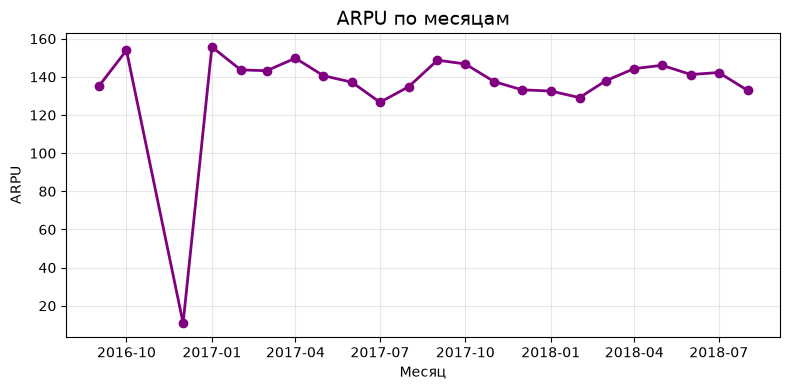

In [25]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(arpu_monthly['order_month'], arpu_monthly['arpu'],
        marker='o', color='purple', linewidth=2)
ax.set_title('ARPU по месяцам', fontsize=14)
ax.set_xlabel('Месяц')
ax.set_ylabel('ARPU')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

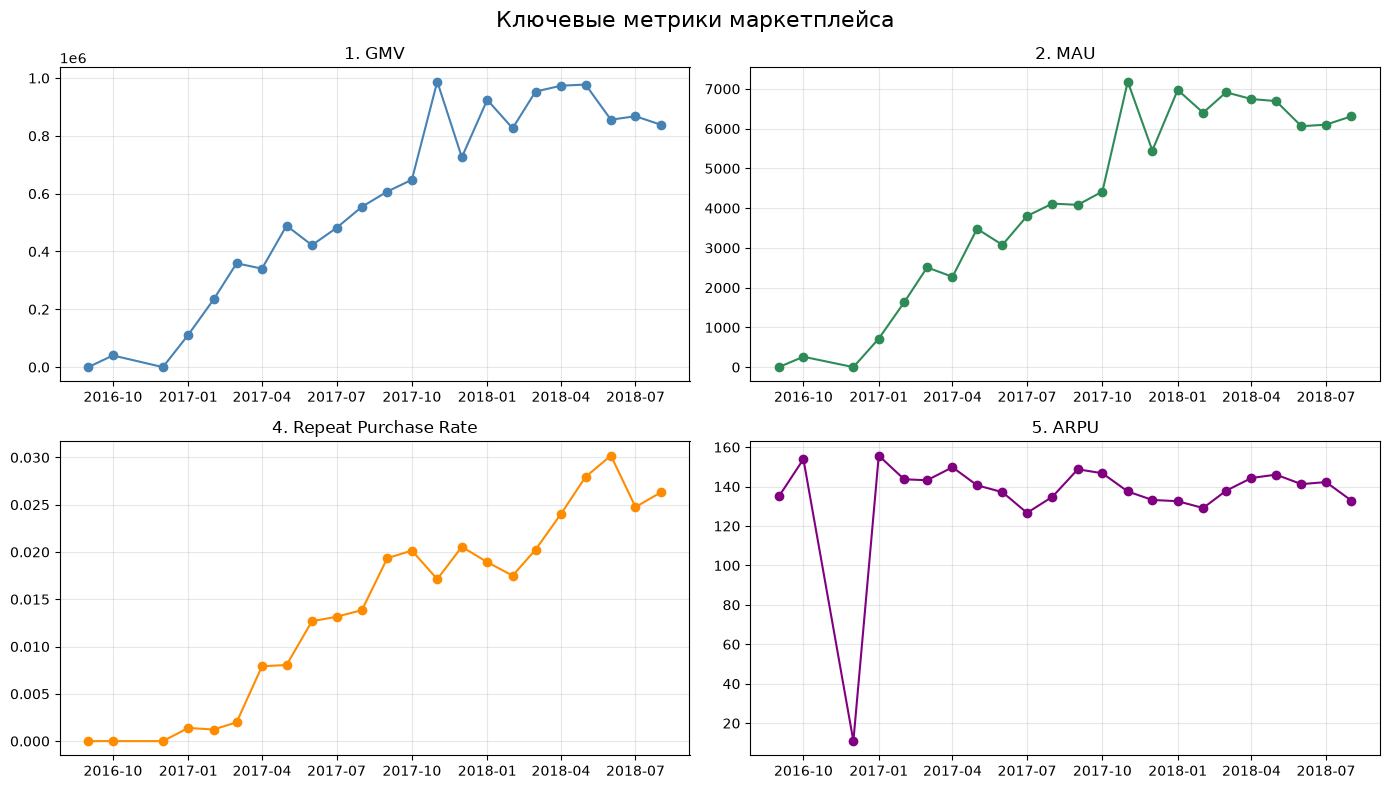

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(gmv_monthly['order_month'], gmv_monthly['gmv'],
                marker='o', color='steelblue')
axes[0, 0].set_title('1. GMV')
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(mau_monthly['order_month'], mau_monthly['mau'],
                marker='o', color='seagreen')
axes[0, 1].set_title('2. MAU')
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(rpr_monthly['order_month'], rpr_monthly['repeat_rate'],
                marker='o', color='darkorange')
axes[1, 0].set_title('4. Repeat Purchase Rate')
axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(arpu_monthly['order_month'], arpu_monthly['arpu'],
                marker='o', color='purple')
axes[1, 1].set_title('5. ARPU')
axes[1, 1].grid(alpha=0.3)

fig.suptitle('Ключевые метрики маркетплейса', fontsize=16)
plt.tight_layout()
plt.show()

GMV и MAU вышли на плато в конце 2017. Repeat Purchase Rate растёт с нуля до ~3%, но остаётся крайне низким. ARPU стабилен.

**Вывод:** маркетплейс исчерпал рост за счёт привлечения новых клиентов. 

Дальнейший рост GMV возможен только двумя путями:
1. Больше новых клиентов — но канал, судя по MAU, уже насыщен.
2. Больше повторных покупок — retention и repeat rate практически нулевые.

**Приоритет:** работать над повторными покупками (метрика №4) и ARPU (метрика №5), а не гнаться за новыми клиентами.

##### **Задача 4. Выбрать одну из 3 основных гипотез с помощью фреймворка ICE.**

По условию:
1. Берём данные с июня 2017 года.
2. Конверсия в повторный заказ = медианный retention 1-го месяца.
3. Считаем, сколько дополнительных заказов даст гипотеза, переводим по шкале в Impact 1–10.

Гипотезы:
1. Исправим баг в процессинге: убираем все отмены (кол-во отменённых заказов с июня 2017, т.е. все станут доставленными)
2. Сократим время до отгрузки: убираем запаздывания → больше повторных заказов (кол-во заказов с запаздыванием × retention 1-го месяца)  
3. Новый способ оплаты: конвертирует в повторный заказ тех, кто раньше не делал повторный (кол-во клиентов, не сделавших повторный заказ × retention 1-го месяца)

In [27]:
# медианный retention 1-го месяца
median_retention_m1

np.float64(0.004939084622983207)

Гипотеза 1 — исправление бага в процессинге

In [28]:
cutoff = pd.Timestamp('2017-06-01')

# Отменённые и недоступные заказы с июня 2017
cancelled = orders[(orders['order_status'].isin(['canceled', 'unavailable'])) & (pd.to_datetime(orders['order_purchase_timestamp']) >= cutoff)]

impact_1_orders = cancelled.shape[0]
print('Доп. заказов (гипотеза 1):', impact_1_orders)

Доп. заказов (гипотеза 1): 974


Гипотеза 2 — сокращение времени до отгрузки

In [29]:
delivered = orders[orders['order_status'] == 'delivered'].copy()
delivered['order_purchase_timestamp'] = pd.to_datetime(delivered['order_purchase_timestamp'])
delivered['order_delivered_customer_date'] = pd.to_datetime(delivered['order_delivered_customer_date'])
delivered['order_estimated_delivery_date'] = pd.to_datetime(delivered['order_estimated_delivery_date'])

delayed = delivered[
    (delivered['order_purchase_timestamp'] >= cutoff) &
    (delivered['order_delivered_customer_date'] > delivered['order_estimated_delivery_date'])
]

impact_2_orders = delayed.shape[0] * median_retention_m1
print('Доп. заказов (гипотеза 2):', impact_2_orders)

Доп. заказов (гипотеза 2): 36.030622324662495


Гипотеза 3 — новый способ оплаты

In [30]:
orders_since_june = delivered_orders[pd.to_datetime(delivered_orders['order_purchase_timestamp']) >= cutoff]

# Число заказов на клиента
orders_per_user = (orders_since_june.groupby('customer_unique_id')['order_id'].nunique())

# Клиенты без повторных заказов (ровно 1 заказ)
no_repeat_users = (orders_per_user == 1).sum()

impact_3_orders = no_repeat_users * median_retention_m1

print('Клиентов без повтора:', no_repeat_users)
print('Доп. заказов (гипотеза 3):', impact_3_orders)

Клиентов без повтора: 80558
Доп. заказов (гипотеза 3): 397.88277905828124


In [31]:
# Переводим в Impact по шкале
def impact_score(x):
    if x <= 50: 
        return 1
    if x <= 150: 
        return 2
    if x <= 350: 
        return 3
    if x <= 750: 
        return 4
    if x <= 1550: 
        return 5
    if x <= 3150: 
        return 6
    if x <= 6350: 
        return 7
    if x <= 12750: 
        return 8
    if x <= 25550: 
        return 9
    return 10

print('Impact 1:', impact_score(impact_1_orders))
print('Impact 2:', impact_score(impact_2_orders))
print('Impact 3:', impact_score(impact_3_orders))

Impact 1: 5
Impact 2: 1
Impact 3: 4


In [32]:
# Считаем ICE
results = pd.DataFrame([
    {'Гипотеза': 'Исправим баг в процессинге', 'Impact': impact_score(impact_1_orders), 'Confidence': 8, 'Ease': 6},
    {'Гипотеза': 'Сократим время отгрузки', 'Impact': impact_score(impact_2_orders), 'Confidence': 10, 'Ease': 4},
    {'Гипотеза': 'Новый способ оплаты', 'Impact': impact_score(impact_3_orders), 'Confidence': 5, 'Ease': 9},
])

results['ICE'] = results['Impact'] * results['Confidence'] * results['Ease']
results.sort_values('ICE', ascending=False)

results

,Гипотеза,Impact,Confidence,Ease,ICE
0,Исправим баг в процессинге,5,8,6,240
1,Сократим время отгрузки,1,10,4,40
2,Новый способ оплаты,4,5,9,180


По фреймворку ICE побеждает гипотеза «Исправим баг в системе процессинга заказов». Она даёт наибольший прирост доставленных заказов (убирает все отмены), команда уверена в эффекте (Confidence=8), а реализация относительно простая (Ease=6).


#### **Отчёт для Пети: почему выручка стоит и что с этим делать**
**Проблема.** 

Маркетплейс вышел на плато: GMV и MAU не растут с конца 2017. Причина — продукт не удерживает клиентов. 

Медианный retention 1-го месяца — 0.49%: из 1000 новых покупателей через месяц возвращается ~5 человек, и дальше retention только падает. 

Только 3% клиентов совершают больше одного заказа — 97% покупают один раз и уходят. 

Ключевая формулировка: рост выручки обеспечивался притоком новых клиентов, но этот канал исчерпан, а повторных покупок почти нет.

<br>

**Диагностика.** 

Когортный анализ показал, что retention критически низкий и не улучшается между когортами, хотя база клиентов растёт. 

По обоим критериям PMF (уровень retention > 5% и его стабильность между когортами) продукт порог не проходит — product/market fit отсутствует. 

Причины: разовый характер покупок, слабый post-purchase опыт, возможные проблемы с доставкой.

<br>

**Метрики.** 

GMV: пик 988 тыс. (ноя 2017) → плато ~850 тыс. 

MAU: пик 7 183 → плато ~6 200. 

Repeat Purchase Rate растёт до ~3%, но остаётся крайне низким. 

ARPU стабилен ~135. 

Вывод: GMV и MAU на плато, Repeat Rate и ARPU не растут — приоритет смещается с привлечения на повторные покупки.

<br>

**Гипотеза.** 

По фреймворку ICE победила гипотеза «исправить баг в процессинге заказов» (ICE = 240): она устраняет ~970 отменённых заказов с июня 2017, команда уверена в эффекте, реализация средней сложности. 

Проверять через A/B-тест по трём метрикам:

Order Cancellation Rate (целевая) — доля отменённых заказов (canceled + unavailable) от всех; гипотеза напрямую её снижает (ожидание ↓ 50–100%).

Delivered Rate (прокси) — доля доставленных заказов от всех; обратная сторона целевой, ловит эффект быстрее (ожидание ↑ 0.5–1 п.п.).

Average Delivery Time (guardrail) — среднее время от заказа до доставки; защищает клиентский опыт от перегрузки логистики (не должен вырасти более чем на 5–10%).

<br>

**Рекомендации.**

Переключить фокус с привлечения на удержание и повторные покупки. 

Первый шаг — исправить баг в процессинге и измерить эффект через A/B-тест. 

Среднесрочно: сегментировать клиентов по категориям/штатам/каналам и найти ниши с высоким retention; развивать post-purchase опыт (email, лояльность, рекомендации); проверить сроки и стабильность доставки. 

<br>

**Итог.**

 Выручка стоит, потому что канал привлечения исчерпан, а удержания нет. PMF отсутствует. Первый шаг — исправить баг в процессинге (ICE = 240), стратегический фокус — Repeat Purchase Rate.